# Synthetic rock schedules for DGSA

Generate regional rock application schedules from a global S-curve used to scale GCAM's donor regional schedule. Global S-curves come from `create-synthetic-s-curves-dgsa.ipynb`. Regional curves end up as `dfrock` files for `gcam_postprocess_region_constApp`. 

Every donor region is multiplied by a shared `factor(t) = target(t) / donor_global(t)`.

Outputs:
- `rock_schedules.parquet` (all schedules, DGSA sites only)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import s3fs

## Config

In [13]:
DGSA_VERSION = "v1.2"
EXP_SET = "exe_central1p5"  # donor schedule (supplies the regional split)
REF_APPRATE = 5.0           # [t/ha/yr] donor dfrock's fixed rate
RCO2_GCAM = 0.3             # [t CO2 / t rock]

S3_BASE = "s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/one-cell-per-region"
DONOR_PKL = f"{S3_BASE}/{EXP_SET}/{REF_APPRATE}-tHaYr-appRate-FIXED/annual_rockflx_densest-ag-region_1deg.pkl"
SCURVE_DIR = f"{S3_BASE}/synthetic-dgsa-{DGSA_VERSION}"
BATCH_CSV = ("s3://carbonplan-carbon-removal/ew-workflows-data/scepter/batch/"
             f"gcam_dgsa_{DGSA_VERSION}_{EXP_SET}_gbas_yearly_ltm_v4_repcells1.csv")  # for the DGSA site list

# --- [ save ] ---
SAVE_TO_S3 = True
OVERWRITE_EXISTING = False
schedules_fn = f"{SCURVE_DIR}/rock_schedules.parquet"

## Read inputs

In [14]:
manifest = pd.read_csv(f"{SCURVE_DIR}/manifest.csv", index_col="schedule_name")
curves = pd.read_csv(f"{SCURVE_DIR}/curves.csv", index_col="year")
df_donor = pd.read_pickle(DONOR_PKL)
sites = list(pd.read_csv(BATCH_CSV, usecols=["region_nospaces"])["region_nospaces"].unique())

years = np.sort(df_donor["time"].unique()).astype(float)
assert np.array_equal(curves.index.values, years), "curves.csv years != donor years"
assert curves.columns.equals(manifest.index), "curves.csv columns != manifest schedule_names"
assert set(sites) <= set(df_donor["region_nospaces"]), "DGSA site missing from donor"
print(f"{len(manifest)} schedules | {len(sites)} DGSA sites: {sites} | years {years[0]:.0f}-{years[-1]:.0f}")

3000 schedules | 7 DGSA sites: ['USA', 'Brazil', 'China', 'EU-15', 'India', 'South_Asia', 'Southeast_Asia'] | years 2020-2100


## Per-year rescaling factor

In [15]:
donor_global = df_donor.groupby("time")["gcam_gross_cdr_mtCO2"].sum().reindex(years).values
has_donor = donor_global > 0

target = curves.mul(has_donor.astype(float), axis=0)
factors = target.div(np.where(has_donor, donor_global, 1.0), axis=0)
assert np.allclose(factors.mul(donor_global, axis=0), target, rtol=1e-12)

print(f"donor is zero in: {years[~has_donor].astype(int).tolist()} (target forced to 0 there)")
max_factor = factors.max()
print(f"max factor per schedule: median {max_factor.median():.2f}x, max {max_factor.max():.1f}x, "
      f"{(max_factor > 20).sum()} schedules > 20x")

donor is zero in: [2020] (target forced to 0 there)
max factor per schedule: median 0.20x, max 17.4x, 0 schedules > 20x


## Build the schedules
Only the DGSA sites are materialized; the per-year factor already guarantees the full 32-region sum hits the target.

In [16]:
MASS_COLS = ["gcam_gross_cdr_mtCO2", "cropland_area_required_ha",
             "cropland_fraction_required", "cropland_fraction_effective"]

f_long = factors.rename_axis(index="time", columns="schedule_name").stack().rename("factor").reset_index()
f_long["time"] = f_long["time"].astype(df_donor["time"].dtype)
df = df_donor[df_donor["region_nospaces"].isin(sites)].merge(f_long, on="time")
for col in MASS_COLS:
    df[col] *= df["factor"]

# paired geochem draw's fixed rate -- same rescale as the DGSA branch of cdr-gcam-globalscaling-constApp*.ipynb
apprate = df["schedule_name"].map(manifest["apprate_base"])
scale = apprate / REF_APPRATE
df["effective_rate_t_ha"] = apprate
df["rockflx_t_ha"] = apprate
df["rockflx_Mt_ha"] = apprate / 1e6
df["rockflx_Mt"] *= scale
df["cropland_area_required_ha"] /= scale
df["cropland_fraction_required"] /= scale
df["cropland_fraction_effective"] = df["cropland_fraction_required"]

schedules = (df.drop(columns="factor")
             [["schedule_name"] + list(df_donor.columns)]
             .sort_values(["schedule_name", "reg_id", "time"]).reset_index(drop=True))
print(f"{len(schedules):,} rows ({schedules.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory)")

1,701,000 rows (308 MB in memory)


## Validate

In [17]:
# [1] shape: every schedule has every site x year
assert len(schedules) == len(manifest) * len(sites) * len(years)
assert schedules.groupby("schedule_name").size().eq(len(sites) * len(years)).all()

# [2] no NaNs / negatives
num = schedules.select_dtypes("number")
assert num.notna().all().all() and (num[MASS_COLS] >= 0).all().all()

# [3] each schedule carries its paired draw's rate
rate = schedules.groupby("schedule_name")["effective_rate_t_ha"].agg(["min", "max"])
assert (rate["min"] == rate["max"]).all() and np.allclose(rate["min"], manifest["apprate_base"].reindex(rate.index))

# [4] rock mass balance: area x rate == GCAM CDR / RCO2 (ties the schedule and rate rescales together)
rock_t = schedules["gcam_gross_cdr_mtCO2"] / RCO2_GCAM * 1e6
assert np.allclose(schedules["cropland_area_required_ha"] * schedules["effective_rate_t_ha"], rock_t, rtol=1e-9)

# [5] independent per-schedule path (as in create-synthetic-global-rock-schedules.ipynb), all 32 regions,
#     for the schedules with the earliest, median, and latest t_mid plus the largest factor
check = [manifest["t_mid"].idxmin(), (manifest["t_mid"] - manifest["t_mid"].median()).abs().idxmin(),
         manifest["t_mid"].idxmax(), max_factor.idxmax()]
for name in check:
    f = pd.Series(factors[name].values, index=years.astype(int), name="factor")
    d = df_donor.merge(f, left_on="time", right_index=True)
    d["gcam_gross_cdr_mtCO2"] *= d["factor"]
    assert np.allclose(d.groupby("time")["gcam_gross_cdr_mtCO2"].sum().values, target[name].values, rtol=1e-10, atol=1e-9)
    d_sites = d[d["region_nospaces"].isin(sites)].sort_values(["reg_id", "time"])["gcam_gross_cdr_mtCO2"].values
    ours = schedules.loc[schedules["schedule_name"] == name, "gcam_gross_cdr_mtCO2"].values
    assert np.allclose(d_sites, ours, rtol=1e-12)
print("all checks passed")

all checks passed


## QC plots
The right panel is the same for every schedule: each schedule inherits the donor's regional split at each calendar year.

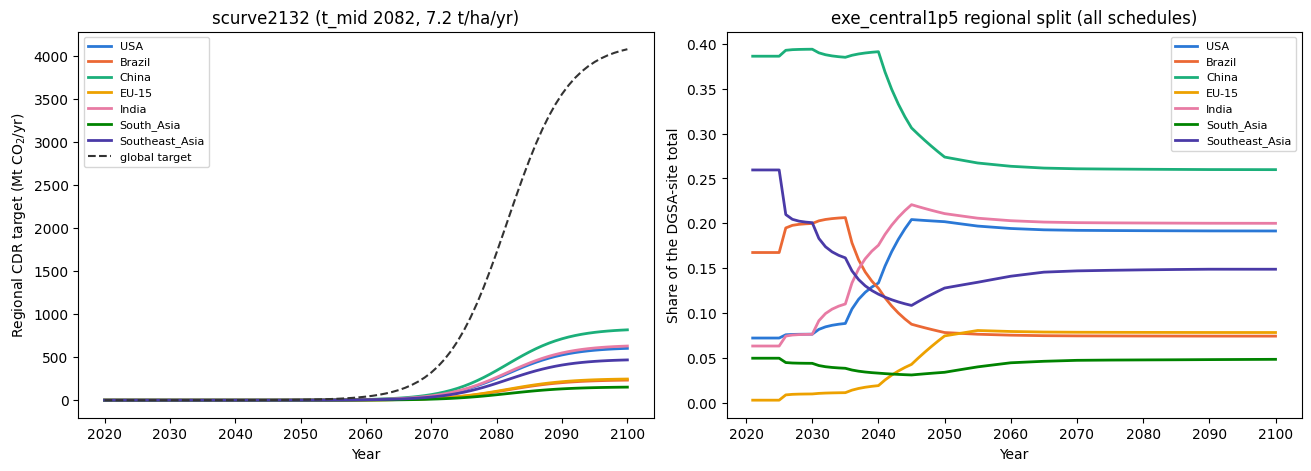

In [18]:
SITE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7"]
INK = "#333333"
name = check[1]  # median-t_mid schedule
ex = schedules[schedules["schedule_name"] == name].pivot(index="time", columns="region_nospaces",
                                                          values="gcam_gross_cdr_mtCO2")[sites]
share = (df_donor.pivot(index="time", columns="region_nospaces", values="gcam_gross_cdr_mtCO2")[sites]
         .pipe(lambda w: w.div(w.sum(axis=1), axis=0)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained")
for site, color in zip(sites, SITE_COLORS):
    axes[0].plot(ex.index, ex[site], color=color, lw=2, label=site)
    axes[1].plot(share.index, share[site], color=color, lw=2, label=site)
axes[0].plot(years, target[name], color=INK, ls="--", lw=1.5, label="global target")
axes[0].set_ylabel(r"Regional CDR target (Mt CO$_2$/yr)")
axes[0].set_title(f"{name} (t_mid {manifest.loc[name, 't_mid']:.0f}, "
                  f"{manifest.loc[name, 'apprate_base']:.1f} t/ha/yr)")
axes[1].set_ylabel("Share of the DGSA-site total")
axes[1].set_title(f"{EXP_SET} regional split (all schedules)")
for ax in axes:
    ax.set_xlabel("Year")
axes[1].legend(fontsize=8, loc="upper right")
axes[0].legend(fontsize=8, loc="upper left")
plt.show()

## Save
Dry run unless `SAVE_TO_S3 = True`.

In [19]:
fs = s3fs.S3FileSystem()

if SAVE_TO_S3:
    if not OVERWRITE_EXISTING and fs.exists(schedules_fn.replace("s3://", "")):
        raise FileExistsError(f"refusing to overwrite (set OVERWRITE_EXISTING = True): {schedules_fn}")
    schedules.to_parquet(schedules_fn, index=False)
    # check_dtype=False: string columns come back pyarrow-backed; values are still compared exactly
    pd.testing.assert_frame_equal(pd.read_parquet(schedules_fn), schedules, check_dtype=False, check_exact=True)
    print(f"saved + round-trip checked: {schedules_fn}")
else:
    print(f"SAVE_TO_S3 is False -- nothing written. Would write: {schedules_fn}")

saved + round-trip checked: s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/one-cell-per-region/synthetic-dgsa-v1.2/rock_schedules.parquet


In [ ]:
# ---